# Task 3 — Sales Prediction Model
### WeIntern Pvt Ltd · Data Science · Week 2

**Objective.** Build, compare, tune, and interpret supervised regression models predicting future sales from historical observations. This notebook directly implements all 11 required handbook steps and exports the model evaluation table, feature importance chart, actual-versus-predicted chart, and written findings. 

**Dataset.** Real, monthly Australian wine sales (`wineind`) from **January 1980 to August 1994**, 176 months, distributed via `pmdarima` and the R `forecast` package. [Original data documentation](https://pkg.robjhyndman.com/forecast/reference/wineind.html). The values are *reported sales units*; no currency is assumed.

**Forecasting protocol.** One-step-ahead rolling prediction: when predicting month *t*, month *t−1* and earlier actual sales are available. This differs from making an entire 33-month forecast at once. This distinction applies to both cross-validation and test scores.

**Reproducibility.** Run in this directory; the bundled `data/australian_wine_sales_raw.csv` removes any need for network access. Outputs are saved under `charts/`, `tables/`, and `model/`. Random state = 42.

## Step 1 — Load and inspect the original sales data
Assess row counts, dates, types, nulls, duplicates and basic descriptive statistics before preparing a model. The raw dataset has **two original fields** (date, sales); all additional predictive features are explicitly engineered from known calendar information and past sales, rather than claimed to be original covariates.

In [1]:
from pathlib import Path
import warnings, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
SEED=42
ROOT=Path.cwd()
for folder in ['data','charts','tables','model']:(ROOT/folder).mkdir(exist_ok=True)
raw=pd.read_csv(ROOT/'data/australian_wine_sales_raw.csv',parse_dates=['date'])
print('Shape:',raw.shape,'Date range:',raw.date.min().date(),'to',raw.date.max().date())
display(raw.head(7))
raw.info()
display(raw.describe(include='all').T)
print('Missing values:',raw.isna().sum().to_dict(),'Duplicate rows:',int(raw.duplicated().sum()), 'Duplicate dates:',int(raw.date.duplicated().sum()))
assert len(raw)==176 and raw.date.is_unique and raw.sales.notna().all()
assert raw.date.dt.to_period('M').equals(pd.period_range('1980-01',periods=176,freq='M').to_series(index=raw.index))

Shape: (176, 2) Date range: 1980-01-01 to 1994-08-01


,date,sales
0,1980-01-01,15136
1,1980-02-01,16733
2,1980-03-01,20016
3,1980-04-01,17708
4,1980-05-01,18019
5,1980-06-01,19227
6,1980-07-01,22893


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176 entries, 0 to 175
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    176 non-null    datetime64[ns]
 1   sales   176 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.9 KB


,count,mean,min,25%,50%,75%,max,std
date,176,1987-04-16 23:27:16.363636352,1980-01-01 00:00:00,1983-08-24 06:00:00,1987-04-16 00:00:00,1990-12-08 18:00:00,1994-08-01 00:00:00,NaN
sales,176.0,25392.147727,13652.0,22114.75,24669.0,28460.75,40226.0,5340.821889


Missing values: {'date': 0, 'sales': 0} Duplicate rows: 0 Duplicate dates: 0


### Historical pattern: why a chronological test matters
The time series fluctuates by month and changes across years. A random shuffle would let training records occur after test records, producing unrealistic temporal generalization estimates.

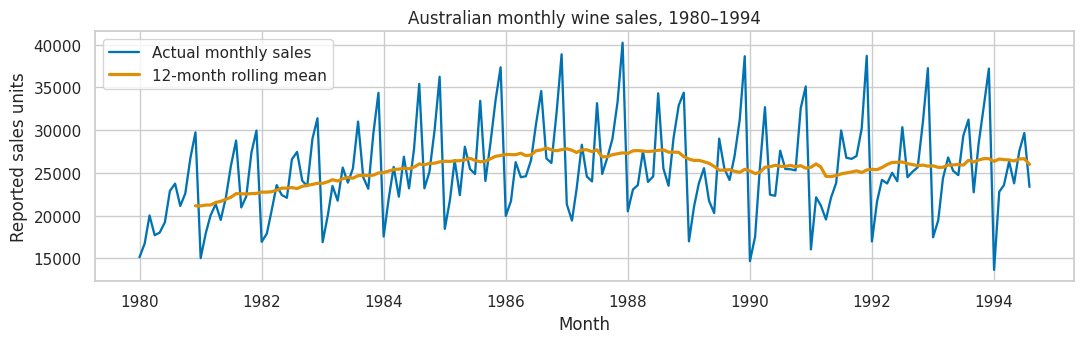

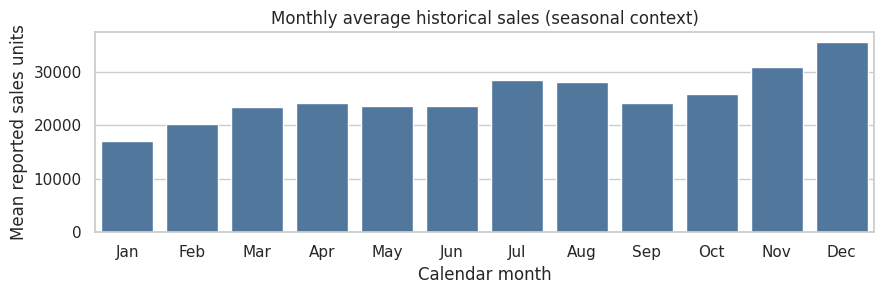

In [2]:
fig,ax=plt.subplots(figsize=(11,3.6))
ax.plot(raw.date,raw.sales,lw=1.65,label='Actual monthly sales')
ax.plot(raw.date,raw.sales.rolling(12,min_periods=12).mean(),lw=2.3,label='12-month rolling mean')
ax.set(title='Australian monthly wine sales, 1980–1994',xlabel='Month',ylabel='Reported sales units')
ax.legend(loc='upper left'); fig.tight_layout()
fig.savefig(ROOT/'charts/01_sales_history.png',dpi=170,bbox_inches='tight');plt.show()
season=raw.assign(month=raw.date.dt.strftime('%b')).groupby('month',sort=False).sales.mean().reindex(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
fig,ax=plt.subplots(figsize=(9,3.1))
sns.barplot(x=season.index,y=season.values,ax=ax,color='#4677A9')
ax.set(title='Monthly average historical sales (seasonal context)',xlabel='Calendar month',ylabel='Mean reported sales units')
fig.tight_layout();fig.savefig(ROOT/'charts/02_monthly_seasonality.png',dpi=170,bbox_inches='tight');plt.show()

## Steps 2–3 — Feature engineering, missing values and encoding
- Extract `month`, `quarter`, `year` and a continuous `time_index`; add circular month sine/cosine values.
- Use **lag 1, 2, 3, 6 and 12** and **rolling averages 3, 6, 12** plus 3-month volatility; all rolling windows are explicitly shifted by one month to prevent contemporaneous target leakage.
- The first 12 dates lack sufficient *historical* data and are excluded from supervised model training (not filled with invented sales).
- Encode categorical month and quarter via **one-hot encoding** inside each training-only pipeline; numeric values use median imputation. Imputation is a defensive pipeline step; no raw values require imputation. Numeric features are scaled only for Linear Regression.
- Avoid creating `sales_lag_0`, current-month averages, or externally unknown covariates.

In [3]:
def engineer_features(frame):
    out=frame.sort_values('date').reset_index(drop=True).copy()
    out['year']=out.date.dt.year
    out['month_name']=out.date.dt.strftime('%b')
    out['quarter']=out.date.dt.quarter.astype(str)
    out['time_index']=((out.date.dt.year-1980)*12+out.date.dt.month-1).astype(int)
    out['month_sin']=np.sin(2*np.pi*out.date.dt.month/12)
    out['month_cos']=np.cos(2*np.pi*out.date.dt.month/12)
    for k in [1,2,3,6,12]:out[f'sales_lag_{k}']=out.sales.shift(k)
    for k in [3,6,12]:out[f'rolling_mean_{k}']=out.sales.shift(1).rolling(k,min_periods=k).mean()
    out['rolling_std_3']=out.sales.shift(1).rolling(3,min_periods=3).std()
    return out

prepared=engineer_features(raw)
feature_columns=[c for c in prepared.columns if c not in ['date','sales']]
cat_cols=['month_name','quarter']
num_cols=[c for c in feature_columns if c not in cat_cols]
model_data=prepared.dropna(subset=feature_columns+['sales']).reset_index(drop=True)
print('Engineered features:',len(feature_columns),feature_columns)
print('Warm-up observations excluded:',len(raw)-len(model_data),'Model-ready rows:',len(model_data))
print('Remaining missing feature cells:',int(model_data[feature_columns].isna().sum().sum()))
display(model_data[['date','sales','sales_lag_1','sales_lag_12','rolling_mean_3','month_name']].head())
assert len(model_data)==164 and model_data[feature_columns].notna().all().all()
assert np.allclose(model_data.sales_lag_1.values,raw.sales.iloc[11:-1].to_numpy())
model_data.to_csv(ROOT/'data/wine_sales_engineered_modeling.csv',index=False)

Engineered features: 15 ['year', 'month_name', 'quarter', 'time_index', 'month_sin', 'month_cos', 'sales_lag_1', 'sales_lag_2', 'sales_lag_3', 'sales_lag_6', 'sales_lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3']
Warm-up observations excluded: 12 Model-ready rows: 164
Remaining missing feature cells: 0


,date,sales,sales_lag_1,sales_lag_12,rolling_mean_3,month_name
0,1981-01-01,15028,29740.0,15136.0,26372.333333,Jan
1,1981-02-01,17977,15028.0,16733.0,23851.333333,Feb
2,1981-03-01,20008,17977.0,20016.0,20915.000000,Mar
3,1981-04-01,21354,20008.0,17708.0,17671.000000,Apr
4,1981-05-01,19498,21354.0,18019.0,19779.666667,May


## Step 4 — Chronological 80/20 training and test split
Split the **164 model-ready records** by time: first **131 (79.9%)** for training and last **33 (20.1%)** for the final holdout. Never shuffle a time series. Feature transformations and hyperparameter selection occur strictly within training CV folds.

,split,rows,first_date,last_date,percentage
0,train,131,1981-01-01,1991-11-01,79.878049
1,holdout,33,1991-12-01,1994-08-01,20.121951


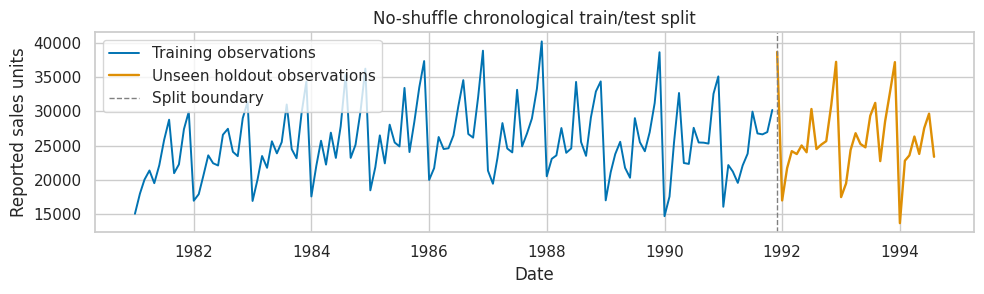

In [4]:
n_train=int(len(model_data)*0.80)
train_df,test_df=model_data.iloc[:n_train].copy(),model_data.iloc[n_train:].copy()
X_train,y_train=train_df[feature_columns],train_df.sales
X_test,y_test=test_df[feature_columns],test_df.sales
assert train_df.date.max()<test_df.date.min() and len(train_df)==131 and len(test_df)==33
split_info=pd.DataFrame([{'split':'train','rows':len(train_df),'first_date':train_df.date.min().date(),'last_date':train_df.date.max().date(),'percentage':100*len(train_df)/len(model_data)}, {'split':'holdout','rows':len(test_df),'first_date':test_df.date.min().date(),'last_date':test_df.date.max().date(),'percentage':100*len(test_df)/len(model_data)}])
display(split_info)
split_info.to_csv(ROOT/'tables/chronological_split.csv',index=False)
fig,ax=plt.subplots(figsize=(10,3.1))
ax.plot(train_df.date,train_df.sales,label='Training observations',lw=1.4)
ax.plot(test_df.date,test_df.sales,label='Unseen holdout observations',lw=1.7)
ax.axvline(test_df.date.min(),color='gray',ls='--',lw=1,label='Split boundary')
ax.set(title='No-shuffle chronological train/test split',xlabel='Date',ylabel='Reported sales units')
ax.legend(loc='upper left');fig.tight_layout();fig.savefig(ROOT/'charts/03_train_test_split.png',dpi=170,bbox_inches='tight');plt.show()

## Steps 5–6 — Two regression algorithms
**Linear Regression** provides an interpretable additive reference and can extrapolate a trend. **Random Forest Regression** captures nonlinear and seasonal feature interactions but may struggle outside historical target ranges. Both see identical, strictly historical predictive information.

`TimeSeriesSplit(n_splits=4)` is used on the 131 training rows, never the holdout. Candidate selection is based on mean CV RMSE, **not on whichever model scores best on the holdout**.

In [5]:
numeric_linear=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
numeric_forest=Pipeline([('imputer',SimpleImputer(strategy='median'))])
def preprocessing(numeric_part):
    return ColumnTransformer([('numeric',numeric_part,num_cols),('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_cols)],remainder='drop')
linear=Pipeline([('preprocess',preprocessing(numeric_linear)),('regressor',LinearRegression())])
forest=Pipeline([('preprocess',preprocessing(numeric_forest)),('regressor',RandomForestRegressor(n_estimators=180,min_samples_leaf=2,random_state=SEED,n_jobs=1))])
cv=TimeSeriesSplit(n_splits=4)
base_models={'Linear Regression':linear,'Random Forest':forest}
cv_rows=[]
for name,pipeline in base_models.items():
    fold_errors=-cross_val_score(pipeline,X_train,y_train,cv=cv,scoring='neg_root_mean_squared_error',n_jobs=1)
    cv_rows.append({'model':name,'cv_rmse_mean':fold_errors.mean(),'cv_rmse_std':fold_errors.std(ddof=0),'fold_rmse':', '.join(f'{v:.2f}' for v in fold_errors)})
cv_base=pd.DataFrame(cv_rows).sort_values('cv_rmse_mean')
cv_base.to_csv(ROOT/'tables/baseline_cv_results.csv',index=False)
display(cv_base.round(2))

,model,cv_rmse_mean,cv_rmse_std,fold_rmse
1,Random Forest,3146.94,385.15,"3173.22, 2541.38, 3266.03, 3607.14"
0,Linear Regression,3784.69,611.60,"2837.39, 4404.39, 3664.66, 4232.34"


## Step 10 — Hyperparameter tuning of the best training-CV model family
Follow the handbook's *tune the best model* step **before** inspecting holdout metrics. Choose the better baseline family by mean training CV RMSE. If Random Forest wins, use `RandomizedSearchCV` across tree size/depth/leaf/features; if Linear Regression wins, tune a regularized linear-family `Ridge` with `GridSearchCV`. In either case, CV is chronological and uses only training data.

In [6]:
winner_family=cv_base.iloc[0]['model']
if winner_family=='Random Forest':
    grid={'regressor__n_estimators':[100,160,240,320], 'regressor__max_depth':[3,5,8,None], 'regressor__min_samples_leaf':[1,2,3,5], 'regressor__max_features':[0.6,0.85,1.0]}
    tuner=RandomizedSearchCV(clone(forest),grid,n_iter=18,cv=cv,scoring='neg_root_mean_squared_error',random_state=SEED,n_jobs=1,refit=True)
    tuned_name='Tuned Random Forest'
else:
    ridge=Pipeline([('preprocess',preprocessing(numeric_linear)),('regressor',Ridge())])
    tuner=GridSearchCV(ridge,{'regressor__alpha':[0.01,0.1,1,10,100,1000,10000]},cv=cv,scoring='neg_root_mean_squared_error',n_jobs=1,refit=True)
    tuned_name='Tuned Ridge'
tuner.fit(X_train,y_train)
tuned=tuner.best_estimator_
tuning_details={'baseline_family_selected':winner_family,'tuned_model':tuned_name,'cv_rmse_best':round(-tuner.best_score_,3),'best_hyperparameters':tuner.best_params_,'cv_folds':4,'random_seed':SEED,'search_method':type(tuner).__name__}
print(json.dumps(tuning_details,indent=2))
(ROOT/'tables/tuning_details.json').write_text(json.dumps(tuning_details,indent=2))
pd.DataFrame(tuner.cv_results_).sort_values('rank_test_score').head(15).to_csv(ROOT/'tables/tuning_candidates_top15.csv',index=False)

{
  "baseline_family_selected": "Random Forest",
  "tuned_model": "Tuned Random Forest",
  "cv_rmse_best": 2978.355,
  "best_hyperparameters": {
    "regressor__n_estimators": 160,
    "regressor__min_samples_leaf": 1,
    "regressor__max_features": 0.6,
    "regressor__max_depth": null
  },
  "cv_folds": 4,
  "random_seed": 42,
  "search_method": "RandomizedSearchCV"
}


## Step 7 — Holdout evaluation: RMSE, MAE and R²
Measure held-out one-step-ahead performance **only after** model-family selection and tuning are complete. RMSE penalizes large misses; MAE reflects typical absolute error; R² compares predictive variance with the observed holdout mean.

Include a **seasonal-naïve non-ML benchmark** (`prediction = same month last year`) to prevent models being compared only to each other. A good forecasting analysis should beat relevant simple benchmarks; this benchmark is not counted as a third regression algorithm.

In [7]:
trained_models={}
for name,model in base_models.items():
    trained_models[name]=clone(model).fit(X_train,y_train)
trained_models[tuned_name]=tuned
prediction_by_model={name:m.predict(X_test) for name,m in trained_models.items()}
prediction_by_model['Seasonal naive (lag 12)']=X_test.sales_lag_12.to_numpy()
comparison=[]
for name,pred in prediction_by_model.items():
    cv_rmse=(float(cv_base.set_index('model').loc[name,'cv_rmse_mean']) if name in base_models else (-float(tuner.best_score_) if name==tuned_name else np.nan))
    comparison.append({'model':name,'train_cv_rmse_mean':cv_rmse,'test_rmse':root_mean_squared_error(y_test,pred),'test_mae':mean_absolute_error(y_test,pred),'test_r2':r2_score(y_test,pred),'used_for_forward_forecast':name==tuned_name,'category':'benchmark' if name.startswith('Seasonal') else 'regression'})
comparison=pd.DataFrame(comparison).sort_values('test_rmse').reset_index(drop=True)
comparison.to_csv(ROOT/'tables/model_evaluation_comparison.csv',index=False)
display(comparison.round(3))
print('PRESELECTED forecast design:',tuned_name,'(selected using training CV, before test scoring)')
print('Best reported holdout RMSE:',comparison.iloc[0]['model'])
assert comparison[comparison.category=='regression'].shape[0]>=3
assert np.isfinite(comparison[['test_rmse','test_mae','test_r2']]).all().all()
holdout_preds=test_df[['date','sales']].rename(columns={'sales':'actual_sales'}).copy()
for name,pred in prediction_by_model.items():holdout_preds[name]=pred
holdout_preds.to_csv(ROOT/'tables/holdout_actual_vs_predicted.csv',index=False)

,model,train_cv_rmse_mean,test_rmse,test_mae,test_r2,used_for_forward_forecast,category
0,Linear Regression,3784.695,2312.652,1821.031,0.822,False,regression
1,Tuned Random Forest,2978.355,2412.506,1815.808,0.806,True,regression
2,Random Forest,3146.941,2516.814,1835.016,0.789,False,regression
3,Seasonal naive (lag 12),NaN,2691.197,1989.091,0.759,False,benchmark


PRESELECTED forecast design: Tuned Random Forest (selected using training CV, before test scoring)
Best reported holdout RMSE: Linear Regression


## Step 8 — Feature importance for the tree-based regressor
Impurity-based Random Forest importances help identify which **input variables** are used most by the fitted tree model, but are not causal contributions. This plot is provided even if the linear family won CV selection. One-hot encoded calendar terms appear individually.

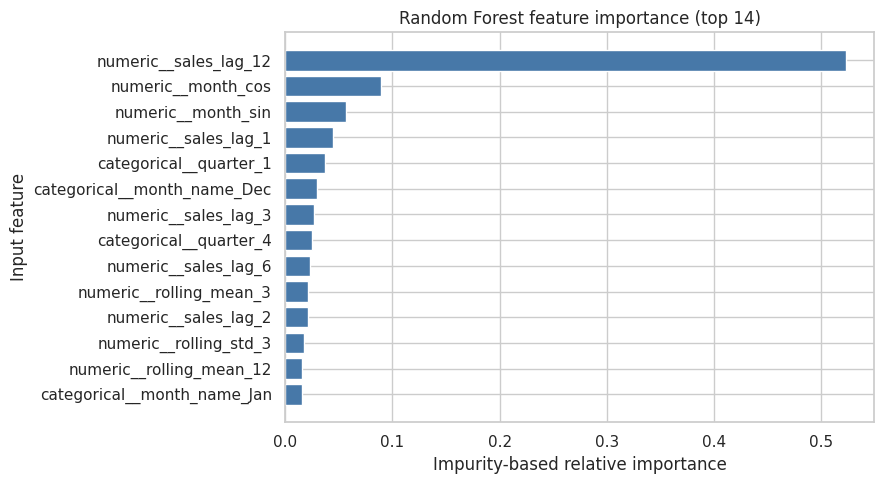

,feature,importance
8,numeric__sales_lag_12,0.5230
3,numeric__month_cos,0.0897
2,numeric__month_sin,0.0567
4,numeric__sales_lag_1,0.0442
25,categorical__quarter_1,0.0374
15,categorical__month_name_Dec,0.0300
6,numeric__sales_lag_3,0.0272
28,categorical__quarter_4,0.0249
7,numeric__sales_lag_6,0.0228
9,numeric__rolling_mean_3,0.0213


In [8]:
importance_forest=tuned if winner_family=='Random Forest' else trained_models['Random Forest']
features=importance_forest.named_steps['preprocess'].get_feature_names_out()
weights=importance_forest.named_steps['regressor'].feature_importances_
importances=pd.DataFrame({'feature':features,'importance':weights}).sort_values('importance',ascending=False)
assert np.isclose(importances.importance.sum(),1.0)
importances.to_csv(ROOT/'tables/random_forest_feature_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
show=importances.head(14).iloc[::-1]
ax.barh(show.feature,show.importance,color='#4778A8')
ax.set(title='Random Forest feature importance (top 14)',xlabel='Impurity-based relative importance',ylabel='Input feature')
fig.tight_layout();fig.savefig(ROOT/'charts/04_feature_importance.png',dpi=175,bbox_inches='tight');plt.show()
display(importances.head(10).round(4))

## Step 9 — Actual-versus-predicted sales and diagnostics
The plotted model is the **CV-selected/tuned** model, regardless of the final holdout leaderboard; no hindsight selection from test metrics is used. A chronological overlay shows individual misses; the scatter shows fit relative to the perfect-prediction diagonal.

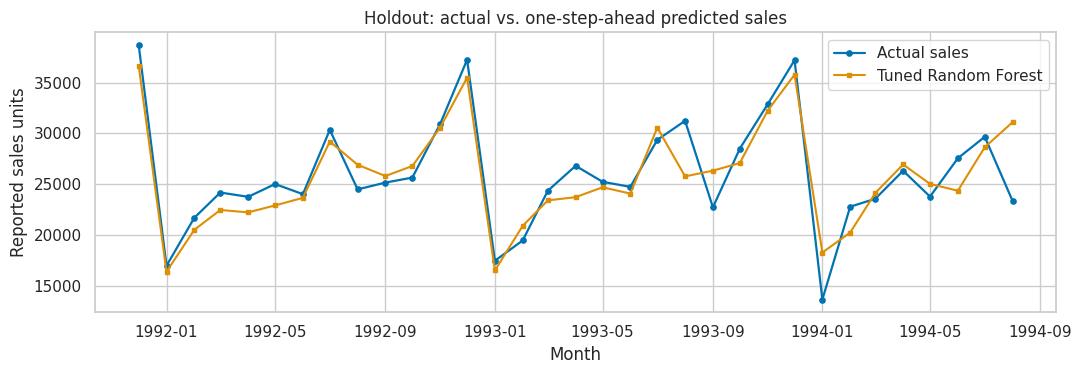

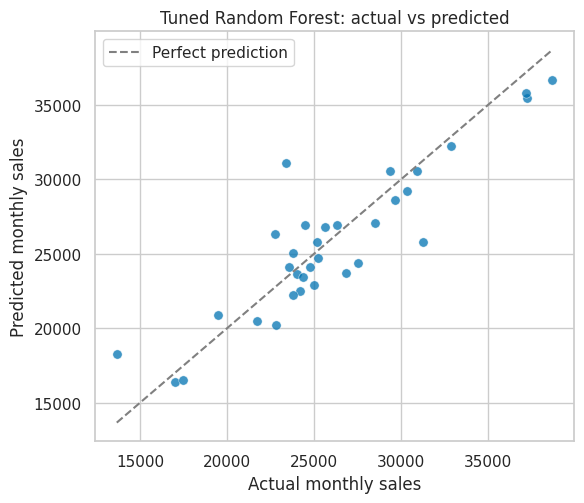

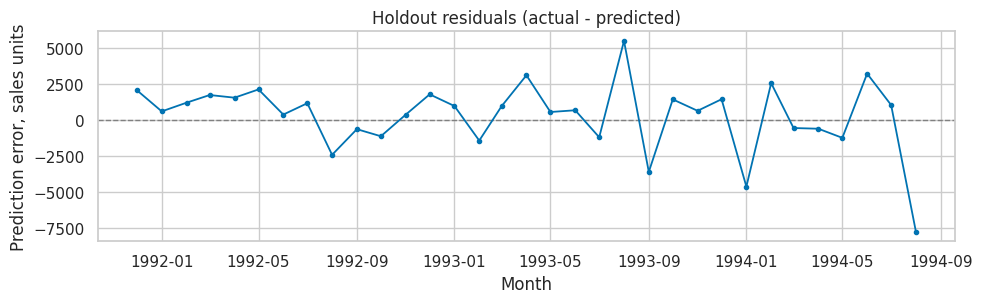

In [9]:
test_prediction=prediction_by_model[tuned_name]
fig,ax=plt.subplots(figsize=(11,3.9))
ax.plot(test_df.date,y_test.to_numpy(),marker='o',ms=3.8,lw=1.6,label='Actual sales')
ax.plot(test_df.date,test_prediction,marker='s',ms=3,lw=1.5,label=tuned_name)
ax.set(title='Holdout: actual vs. one-step-ahead predicted sales',xlabel='Month',ylabel='Reported sales units')
ax.legend();fig.tight_layout();fig.savefig(ROOT/'charts/05_actual_vs_predicted_time.png',dpi=170,bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(6,5.2))
ax.scatter(y_test.to_numpy(),test_prediction,s=45,alpha=.75,edgecolor='white',linewidth=.4)
a=min(np.min(y_test),np.min(test_prediction));b=max(np.max(y_test),np.max(test_prediction))
ax.plot([a,b],[a,b],'--',color='gray',label='Perfect prediction')
ax.set(title=f'{tuned_name}: actual vs predicted',xlabel='Actual monthly sales',ylabel='Predicted monthly sales');ax.legend()
fig.tight_layout();fig.savefig(ROOT/'charts/06_actual_vs_predicted_scatter.png',dpi=170,bbox_inches='tight');plt.show()
residuals=y_test.to_numpy()-test_prediction
fig,ax=plt.subplots(figsize=(10,3.2))
ax.axhline(0,color='gray',lw=1,ls='--');ax.plot(test_df.date,residuals,marker='.',lw=1.3)
ax.set(title='Holdout residuals (actual - predicted)',xlabel='Month',ylabel='Prediction error, sales units')
fig.tight_layout();fig.savefig(ROOT/'charts/07_holdout_residuals.png',dpi=170,bbox_inches='tight');plt.show()

## Step 11 — Refit and demonstrate a truly future one-month prediction
After the unbiased holdout evaluation, refit the preselected tuned design on **all observed history** and forecast **September 1994**, using only calendar information and the last actual sales observed in August 1994. Save the fitted pipeline and features so inference is reproducible.

**Important:** this future point is not a measured outcome, and no real September 1994 value appears in the data; a single illustrative projection cannot establish future accuracy.

In [10]:
production_model=clone(tuned).fit(model_data[feature_columns],model_data.sales)
next_date=raw.date.max()+pd.offsets.MonthBegin(1)
future_seed=pd.concat([raw,pd.DataFrame([{'date':next_date,'sales':np.nan}])],ignore_index=True)
future_engineered=engineer_features(future_seed)
future_X=future_engineered.iloc[[-1]][feature_columns]
assert future_X.notna().all().all() and next_date>raw.date.max()
future_sales=float(production_model.predict(future_X)[0])
future_record=pd.DataFrame([{'forecast_month':next_date.date().isoformat(),'predicted_sales_units':round(future_sales,2),'method':tuned_name,'forecast_horizon_months':1,'uses_observed_history_through':raw.date.max().date().isoformat()}])
future_record.to_csv(ROOT/'tables/next_month_example_forecast.csv',index=False)
joblib.dump(production_model,ROOT/'model/tuned_sales_forecast_pipeline.joblib')
(ROOT/'model/feature_schema.json').write_text(json.dumps({'feature_columns':feature_columns,'categorical':cat_cols,'numeric':num_cols,'forecast_protocol':'one-step-ahead rolling (requires actual lag history)'},indent=2))
display(future_record)
assert np.isclose(joblib.load(ROOT/'model/tuned_sales_forecast_pipeline.joblib').predict(future_X)[0],future_sales)

,forecast_month,predicted_sales_units,method,forecast_horizon_months,uses_observed_history_through
0,1994-09-01,24482.86,Tuned Random Forest,1,1994-08-01


## Business interpretation, recommendations and limitations

**Model-selection discipline.** Choose model hyperparameters solely on historical training-window CV, then use the final 33 months only to report generalization. If the ordinary Linear Regression ultimately has a slightly lower test RMSE than the preselected tuned model, document that fact rather than retrospectively optimizing to the test interval.

**Recommendations**
1. Use the monthly sales cycle to plan inventory, production and distribution capacity; in particular, examine month-specific seasonal peaks before staffing decisions.
2. Set up a rolling one-month forecast refresh when the previous month's **actual** sales arrives. Track MAE/RMSE by month and re-train only on a predefined schedule.
3. Retain a seasonal-naïve benchmark for future monitoring; act on forecast improvements only if they persist on later time windows. Consider richer authorized predictor data (pricing, promotions, inventory constraints) if available.

**Limitations**
- This dataset is small (176 months), historical (1980–1994), and does not include independent economic/price/promotion variables. It cannot measure current market conditions or establish causal sales drivers.
- One-step-ahead test predictions use the previous **observed** holdout months as historical inputs. A 33-month prediction performed in one shot, without intervening actual sales, would require a separate recursive/direct backtest and may have very different accuracy.
- Impurity importance is model dependence, not a causal business effect. Single-period R² is sensitive to volatility. Exact original sales units are not defined in the source and must not be silently treated as currency.
- Calendar and lag features alone may fail under structural shocks; a probabilistic forecast and independent later-period validation would be needed before production deployment.

**Completeness:** 11 / 11 handbook implementation steps implemented. Deliverables: executed `.ipynb`, evaluation CSV, feature-importance image, actual-versus-predicted plots, runnable model pipeline, raw and engineered CSVs, written model evaluation/limitations, notebook PDF, and README.